# 01 · EDA — AWARE Prioritisation Challenge

**Pregunta:** en cada snapshot AWARE lista ~36 tareas abiertas; ¿en cuál trabaja el controlador? Entregamos 3 `row_index` por muestra y la métrica es *top-3 hit rate*.

Este notebook **solo mira los datos**; los modelos van en `src/`. Sigue las reglas de `EQUIPO.md`:
- Todo se ve **por fold** (`Data/folds.csv`, GroupKFold de 5 por `atco`). Cualquier cosa que se «aprenda» de las etiquetas (prior por tipo, sentido de una feature, PCA) se ajusta en los otros 4 folds y se mide en el apartado.
- Cada snapshot se mira **solo con sus propias filas**: nada de snapshots anteriores o posteriores de la sesión.

1. Estructura del dataset y reparto de folds
2. La etiqueta: qué tipos se eligen (lift) y si es estable entre folds
3. Variabilidad entre controladores y escenarios
4. Valores vacíos
5. Qué distingue a la tarea elegida
6. Poder de cada feature como ranker (por fold) y correlaciones
7. PCA (pesos guardados en `models/pca_eda.npz`)
8. Conclusiones

> Convención: «muestra» = un snapshot (`sample_id`); «fila» = una tarea del snapshot.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
import seaborn as sns
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, MODELS = ROOT / "Data", ROOT / "models"

TYPES = ['entry_conflict_resolution', 'exit_conflict_resolution', 'entry_coordination', 'exit_coordination',
         'assume_aircraft', 'transfer_aircraft', 'conflict_resolution', 'non_conformance_resolution',
         'qos_improvement', 'entry_conditions', 'exit_conditions', 'aircraft_request', 'zone_conflict',
         'return_to_route']
NOT_FEATS = ["sample_id", "target_index", "session", "atco", "scenario", "timestamp", "task_name", "row_index", "task_index"]

# Paleta categórica validada (orden fijo) + neutros
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4",
         green="#008300", violet="#6250d6", red="#e34948", ink="#0b0b0b", ink2="#52514e", grid="#e4e3df")
TARGET, OTHER = C["orange"], C["blue"]   # elegida vs resto, en todo el notebook
FOLD_C = [C["blue"], C["orange"], C["aqua"], C["yellow"], C["violet"]]

mpl.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C["ink2"], "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"], "ytick.color": C["ink2"],
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left", "legend.frameon": False,
    "font.size": 9.5, "lines.linewidth": 2,
})
pd.set_option("display.max_columns", 60, "display.width", 160)

In [2]:
tr = pd.read_csv(DATA / "train.csv").assign(split="train")
va = pd.read_csv(DATA / "validation.csv").assign(split="validation")
te = pd.read_csv(DATA / "test.csv").assign(split="test", target_index=np.nan)
d = pd.concat([tr, va, te], ignore_index=True)

d["type"] = d.task_index.map(dict(enumerate(TYPES)))
d["cs"] = [n[len(TYPES[t]) + 1:].split("_")[0] for n, t in zip(d.task_name, d.task_index)]   # avión de la tarea
folds = pd.read_csv(DATA / "folds.csv")
d["fold"] = d.atco.map(folds.set_index("atco").fold)                                          # NaN en test
d = d.sort_values(["sample_id", "row_index"]).reset_index(drop=True)

lab = d[d.split != "test"].copy()                 # train + validation, juntos (regla 5)
assert lab.fold.notna().all(), "hay controladores etiquetados sin fold: regenerar Data/folds.csv"
lab["fold"] = lab.fold.astype(int)
assert (lab.groupby("sample_id").target_index.sum() == 1).all(), "alguna muestra no tiene exactamente una respuesta"
pos = lab[lab.target_index == 1].copy()           # una fila por muestra: la respuesta
num = [c for c in lab.columns if lab[c].dtype.kind in "fi" and c not in NOT_FEATS + ["fold"]]
print(d.groupby("split").agg(muestras=("sample_id", "nunique"), filas=("sample_id", "size"),
                             sesiones=("session", "nunique"), atcos=("atco", "nunique")))
print(f"{len(num)} columnas numéricas candidatas a feature")

            muestras   filas  sesiones  atcos
split                                        
test            1863   66409         5      2
train          11923  432578        34     16
validation      1252   42110         3      2
87 columnas numéricas candidatas a feature


## 1 · Estructura del dataset y reparto de folds

Cada sesión = controlador × escenario. Cada controlador va entero a un fold. Test son los controladores 020 (leaderboard público, que también está en validation y por tanto en un fold) y 023 (privado, el que decide, sin etiquetas).

In [3]:
smp = lab.drop_duplicates("sample_id")
fs = smp.groupby("fold").agg(muestras=("sample_id", "size"), atcos=("atco", lambda s: " ".join(f"{a:03d}" for a in sorted(s.unique()))),
                             sesiones=("session", "nunique"), seq_len=("seq_len", "mean"))
fs["aviones/muestra"] = lab.groupby("fold").apply(lambda g: g.groupby("sample_id").cs.nunique().mean())
fs["% twin"] = pos.groupby("fold").l_twin_AE.mean()
fs.style.format({"seq_len": "{:.1f}", "aviones/muestra": "{:.1f}", "% twin": "{:.1%}"})

,muestras,atcos,sesiones,seq_len,aviones/muestra,% twin
fold,,,,,,
0,2483,007 014 018,7,35.1,18.4,33.1%
1,2757,001 003 004 015,8,35.3,18.4,33.7%
2,2730,002 006 009 016,8,36.9,18.9,30.7%
3,2469,008 017 019,7,34.3,18.1,27.7%
4,2736,005 010 011 020,7,38.3,19.3,24.3%


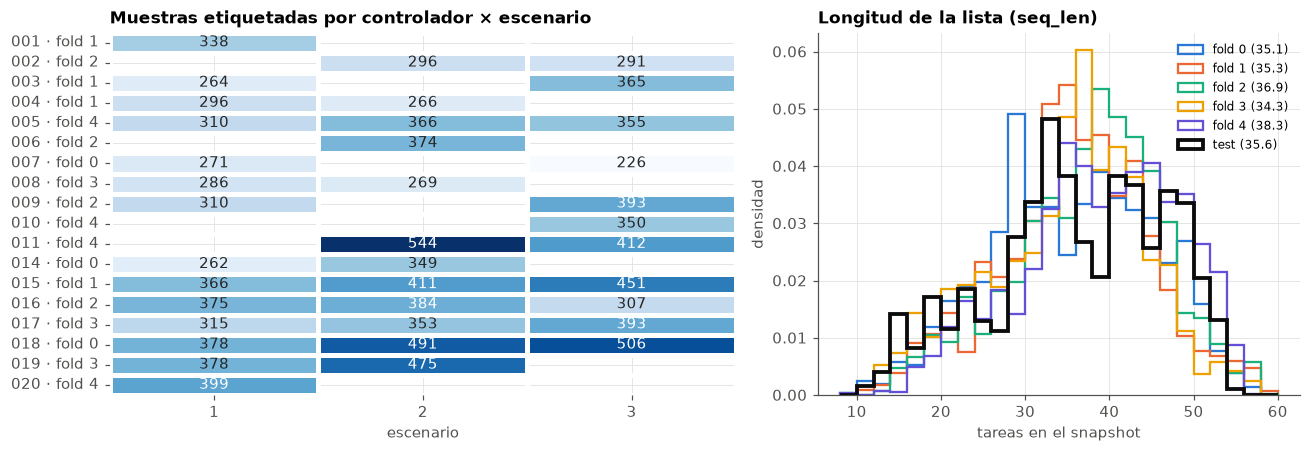

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1.3, 1]))
piv = smp.pivot_table(index="atco", columns="scenario", values="sample_id", aggfunc="size")
fold_of = folds.set_index("atco").fold
sns.heatmap(piv, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax[0], linewidths=2, linecolor="white")
ax[0].set_yticklabels([f"{int(a):03d} · fold {fold_of[int(a)]}" for a in piv.index], rotation=0)
ax[0].set(title="Muestras etiquetadas por controlador × escenario", xlabel="escenario", ylabel="")

for f in range(5):
    x = smp[smp.fold == f].seq_len
    ax[1].hist(x, bins=np.arange(8, 61, 2), density=True, histtype="step", lw=1.5, color=FOLD_C[f], label=f"fold {f} ({x.mean():.1f})")
x = d[d.split == "test"].drop_duplicates("sample_id").seq_len
ax[1].hist(x, bins=np.arange(8, 61, 2), density=True, histtype="step", lw=2.5, color=C["ink"], label=f"test ({x.mean():.1f})")
ax[1].set(title="Longitud de la lista (seq_len)", xlabel="tareas en el snapshot", ylabel="densidad"); ax[1].legend(fontsize=8)
plt.tight_layout()

**Lectura:** ~350 muestras por sesión de ~1 h, pero solo hay muestra cuando el controlador estaba haciendo algo etiquetado. Los folds quedan equilibrados en muestras y la longitud de la lista es parecida entre folds y test. Elegir 3 de ~36 al azar ≈ 9 % → ese es el suelo.

## 2 · La etiqueta: qué tipos se eligen

Proporción de **filas** de cada tipo frente a proporción de **respuestas**. El cociente es el *lift*: >1 = el controlador lo elige más de lo que aparece.

,% filas,% respuestas,lift,P(elegida | presente),% muestras con el tipo
type,,,,,
transfer_aircraft,6.4%,26.8%,4.20,11.7%,90.0%
assume_aircraft,16.6%,25.5%,1.54,4.3%,98.3%
zone_conflict,11.2%,16.1%,1.44,4.0%,99.1%
entry_coordination,29.8%,8.1%,0.27,0.8%,98.1%
return_to_route,3.5%,7.1%,2.04,5.7%,72.3%
exit_coordination,12.7%,5.7%,0.45,1.2%,99.6%
exit_conditions,7.7%,3.4%,0.44,1.2%,93.4%
conflict_resolution,2.3%,3.0%,1.27,3.5%,33.5%
qos_improvement,6.3%,2.0%,0.31,0.9%,86.7%


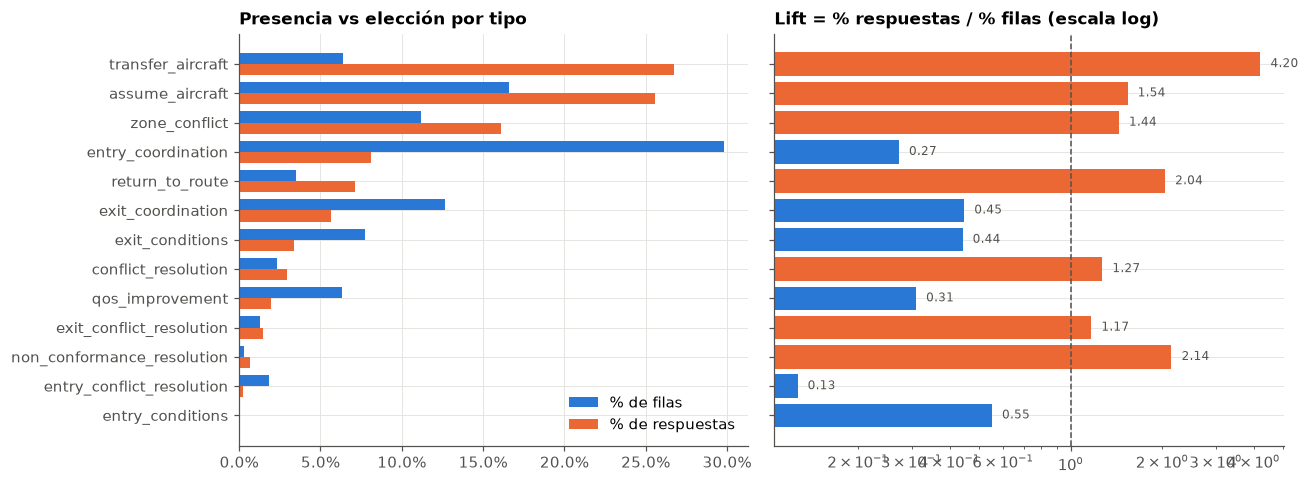

In [5]:
rows = lab.type.value_counts(normalize=True).rename("% filas")
ans = pos.type.value_counts(normalize=True).rename("% respuestas")
tt = pd.concat([rows, ans], axis=1).fillna(0)
tt["lift"] = tt["% respuestas"] / tt["% filas"]
tt["P(elegida | presente)"] = lab.groupby("type").target_index.mean()
tt["% muestras con el tipo"] = lab.groupby("type").sample_id.nunique() / lab.sample_id.nunique()
tt = tt.sort_values("% respuestas", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
y = np.arange(len(tt)); h = 0.38
ax[0].barh(y - h/2, tt["% filas"], h, color=OTHER, label="% de filas")
ax[0].barh(y + h/2, tt["% respuestas"], h, color=TARGET, label="% de respuestas")
ax[0].set_yticks(y, tt.index); ax[0].invert_yaxis(); ax[0].legend(loc="lower right")
ax[0].xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax[0].set_title("Presencia vs elección por tipo")
ax[1].barh(y, tt.lift, color=[TARGET if v > 1 else OTHER for v in tt.lift])
ax[1].axvline(1, color=C["ink2"], lw=1, ls="--"); ax[1].set_xscale("log")
ax[1].set_title("Lift = % respuestas / % filas (escala log)")
for yi, v in zip(y, tt.lift): ax[1].text(v * 1.08, yi, f"{v:.2f}", va="center", fontsize=8, color=C["ink2"])
plt.tight_layout()
tt.style.format({c: "{:.1%}" for c in tt.columns if c != "lift"} | {"lift": "{:.2f}"})

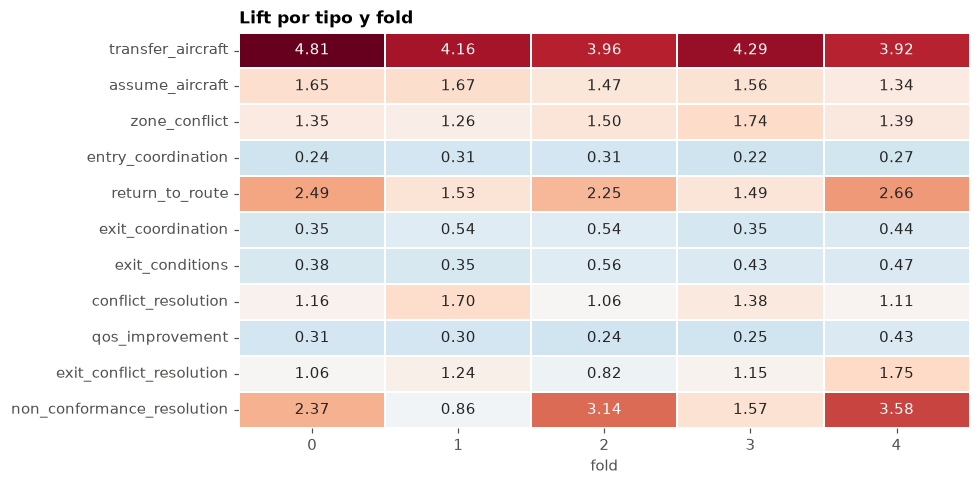

In [6]:
# ¿Es estable el lift entre folds? Si varía mucho, un prior por tipo fijo no generaliza a controladores nuevos
main = tt.index[tt["% respuestas"] > 0.005]
lift_f = pd.DataFrame({f: pos[pos.fold == f].type.value_counts(normalize=True) / lab[lab.fold == f].type.value_counts(normalize=True)
                       for f in range(5)}).reindex(main)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(lift_f, annot=True, fmt=".2f", cmap="RdBu_r", center=1, cbar=False, linewidths=1, linecolor="white", ax=ax)
ax.set(title="Lift por tipo y fold", xlabel="fold", ylabel=""); plt.tight_layout()

In [7]:
# Caso twin: avión con assume + entry_coordination a la vez
tw = pos[pos.l_twin_AE == 1]
print(f"Muestras cuya respuesta es un twin: {len(tw)/len(pos):.1%}")
print(pd.crosstab(tw.fold, tw.type, normalize="index").round(3).to_string())

Muestras cuya respuesta es un twin: 29.9%
type  assume_aircraft  entry_conflict_resolution  entry_coordination
fold                                                                
0               0.778                      0.000               0.222
1               0.731                      0.011               0.258
2               0.695                      0.001               0.304
3               0.761                      0.000               0.239
4               0.683                      0.000               0.317


**Lectura:**
- `transfer_aircraft` y `assume_aircraft` son la mitad de las respuestas. `zone_conflict` y `return_to_route` también sobre-representan.
- `entry_coordination` es el 30 % de las filas pero solo el 8 % de respuestas: casi siempre convive con un `assume_aircraft` del mismo avión (caso «twin»), donde se elige assume ~3 de cada 4 veces.
- `aircraft_request` (11) no aparece; `entry_conditions` (9) es residual.
- Mirar la tabla por fold: los tipos cuyo lift cambia mucho entre folds son los que más dependen del controlador.

## 3 · Variabilidad entre controladores y escenarios

¿Todos los controladores reparten su atención igual? Si hay mucho estilo personal, un modelo debe ser robusto (los de test no se han visto).

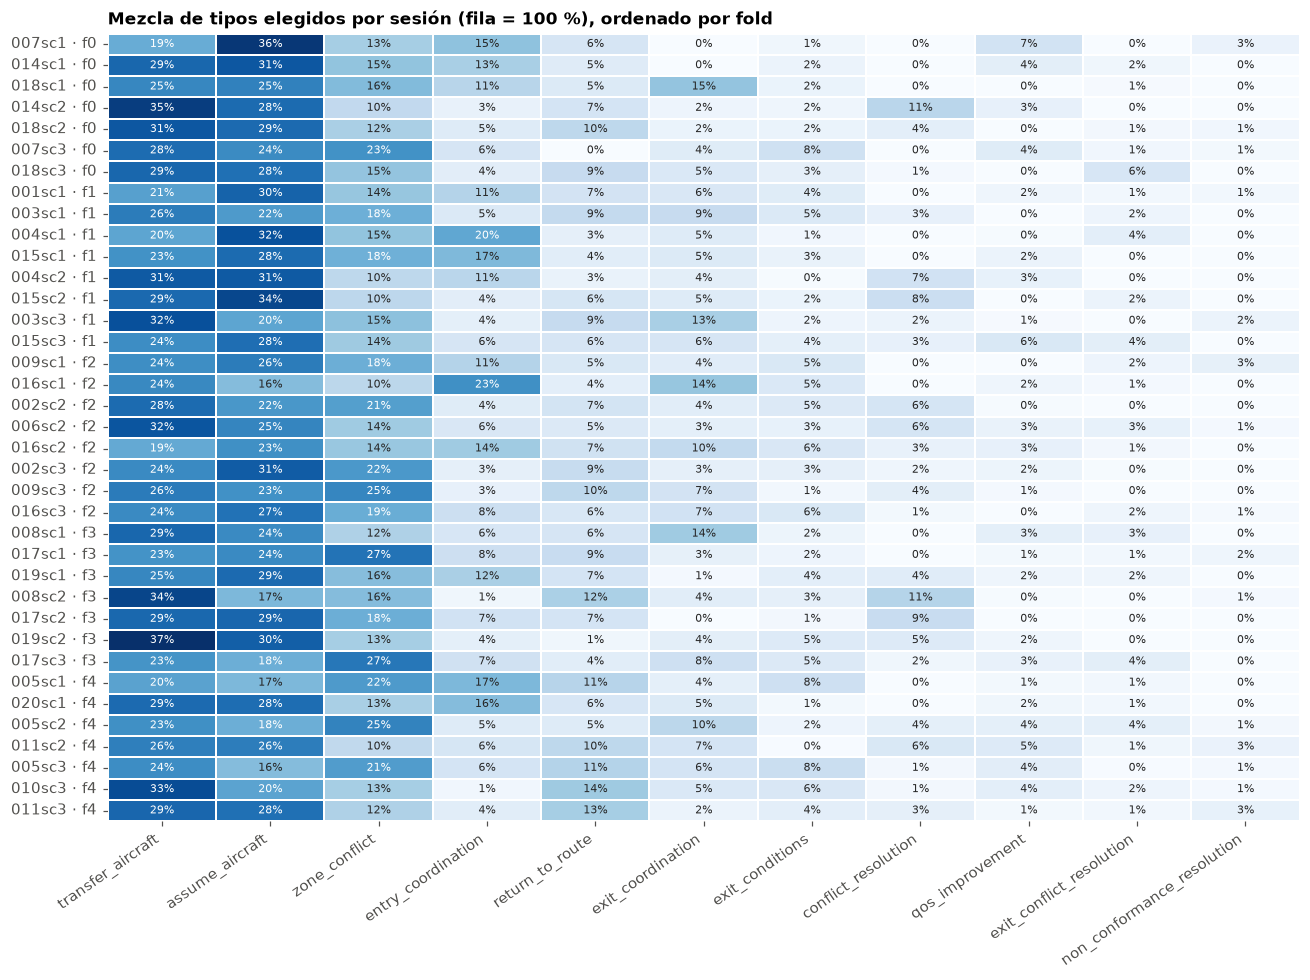

In [8]:
mix = pd.crosstab(pos.session, pos.type, normalize="index")[main]
mix = mix.loc[pos.drop_duplicates("session").sort_values(["fold", "scenario", "session"]).session]
mix.index = [f"{s} · f{fold_of[int(s[:3])]}" for s in mix.index]
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(mix, cmap="Blues", annot=True, fmt=".0%", annot_kws=dict(size=7), cbar=False, linewidths=1, linecolor="white", ax=ax)
ax.set(title="Mezcla de tipos elegidos por sesión (fila = 100 %), ordenado por fold", xlabel="", ylabel="")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right"); plt.tight_layout()

In [9]:
# ¿Qué varía más la mezcla de tipos elegidos: el escenario, el controlador o el fold?
from scipy.stats import chi2_contingency
for g in ["scenario", "atco", "fold"]:
    ct = pd.crosstab(pos[g], pos.type)
    chi2, p, dof, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"Cramér's V tipo ~ {g:8s}: {v:.3f}")
pd.crosstab(pos.scenario, pos.type, normalize="index")[main].style.format("{:.0%}").background_gradient("Blues", axis=None)

Cramér's V tipo ~ scenario: 0.159
Cramér's V tipo ~ atco    : 0.096
Cramér's V tipo ~ fold    : 0.068


type,transfer_aircraft,assume_aircraft,zone_conflict,entry_coordination,return_to_route,exit_coordination,exit_conditions,conflict_resolution,qos_improvement,exit_conflict_resolution,non_conformance_resolution
scenario,,,,,,,,,,,
1,24%,26%,16%,13%,6%,6%,3%,1%,2%,1%,1%
2,29%,26%,14%,6%,7%,5%,3%,6%,2%,1%,1%
3,27%,24%,18%,5%,9%,6%,4%,2%,2%,2%,1%


**Lectura:** la mezcla de tipos depende más del **escenario** (el tráfico y las zonas militares activas cambian qué tareas existen, p. ej. el peso de `zone_conflict`) que del **controlador**. Aun así, dentro de un mismo escenario las sesiones difieren → el prior por tipo debe ser condicional al contexto del snapshot (qué tareas hay en la lista), no fijo.

## 4 · Valores vacíos

Los vacíos significan «no aplica». ¿De qué dependen? Si dependen de `is_assumed`, la propia presencia de NaN es información (LightGBM la aprovecha de forma nativa; en redes, relleno + indicador).

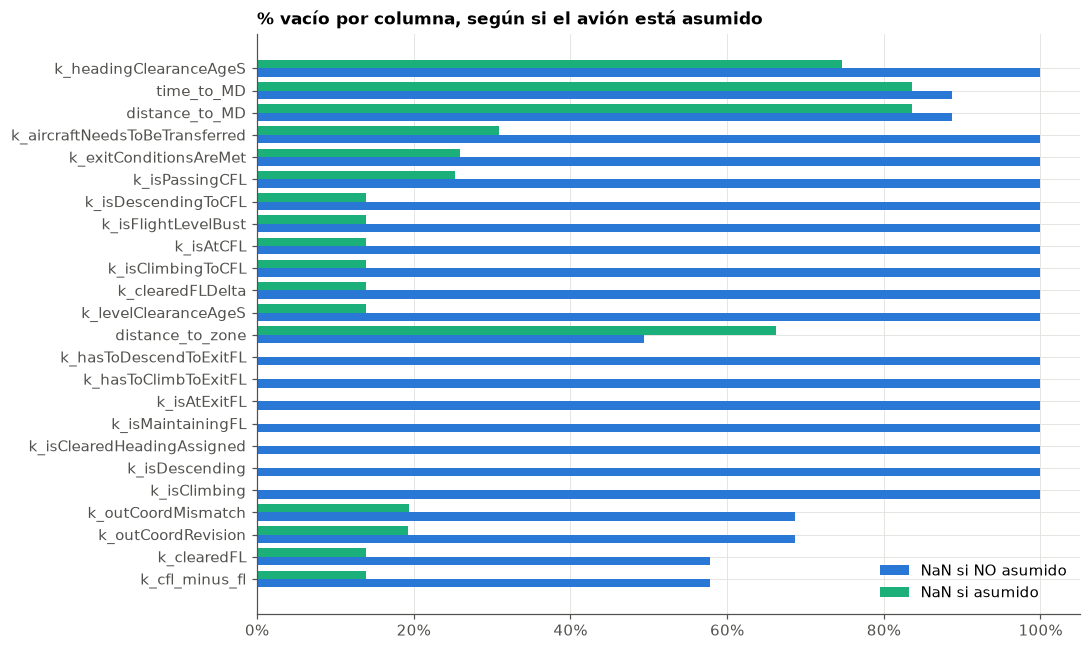

In [10]:
na = lab.isna().mean()
na = na[na > 0.01].sort_values()
by_ass = lab.groupby("is_assumed")[na.index].apply(lambda g: g.isna().mean()).T
by_ass.columns = ["NaN si NO asumido", "NaN si asumido"]
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(by_ass)); h = 0.38
ax.barh(y - h/2, by_ass.iloc[:, 0], h, color=OTHER, label=by_ass.columns[0])
ax.barh(y + h/2, by_ass.iloc[:, 1], h, color=C["aqua"], label=by_ass.columns[1])
ax.set_yticks(y, by_ass.index); ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.set_title("% vacío por columna, según si el avión está asumido"); ax.legend(loc="lower right"); plt.tight_layout()

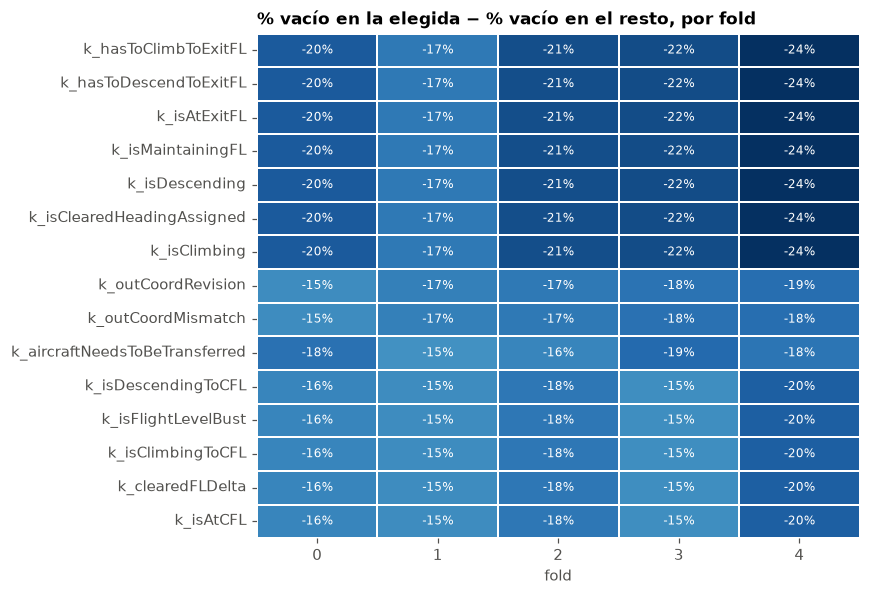

In [11]:
# ¿Estar vacía da información? % vacío en la elegida vs en el resto, y si es estable entre folds
na_t = pd.DataFrame({f: lab[lab.fold == f].groupby("target_index")[na.index].apply(lambda g: g.isna().mean()).T.pipe(lambda x: x[1] - x[0])
                     for f in range(5)})
na_t = na_t.loc[na_t.mean(axis=1).abs().sort_values(ascending=False).index[:15]]
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(na_t, annot=True, fmt="+.0%", cmap="RdBu_r", center=0, cbar=False, linewidths=1, linecolor="white", ax=ax, annot_kws=dict(size=8))
ax.set(title="% vacío en la elegida − % vacío en el resto, por fold", xlabel="fold", ylabel=""); plt.tight_layout()

**Lectura:** los `k_*` están vacíos casi siempre que el avión no está asumido; `distance_to_MD/time_to_MD` solo existen con conflicto, `distance_to_zone` solo si la ruta cruza zona. **No imputar con 0.** Si una diferencia de vacío es del mismo signo en los 5 folds, el indicador de vacío es una feature fiable.

## 5 · ¿Qué distingue a la tarea elegida?

Comparar la elegida con «todas las demás» mezcla tipos; por eso miramos también **dentro del mismo tipo**. Primero, tiempo al borde del sector (negativo = dentro).

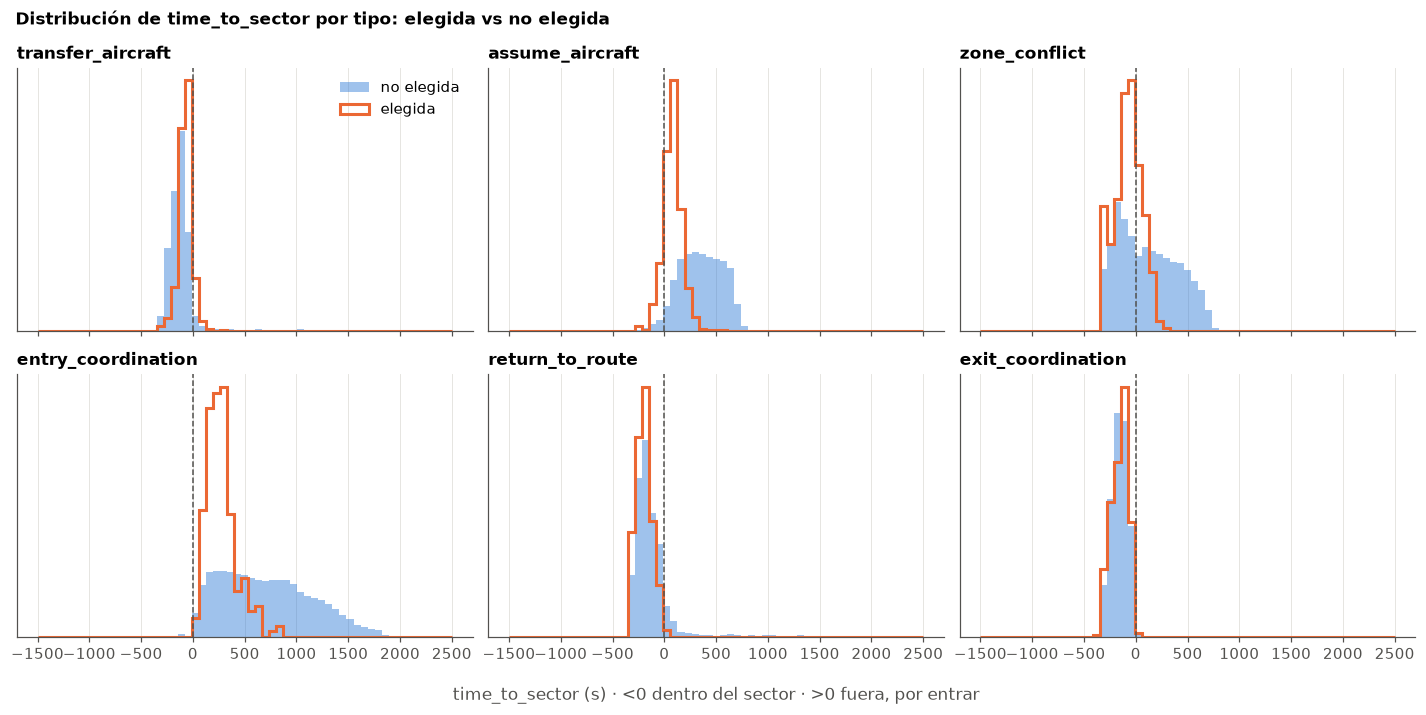

In [12]:
top_types = ["transfer_aircraft", "assume_aircraft", "zone_conflict", "entry_coordination", "return_to_route", "exit_coordination"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
bins = np.linspace(-1500, 2500, 60)
for ax, ty in zip(axes.flat, top_types):
    g = lab[lab.type == ty]
    ax.hist(g[g.target_index == 0].time_to_sector, bins, density=True, color=OTHER, alpha=0.45, label="no elegida")
    ax.hist(g[g.target_index == 1].time_to_sector, bins, density=True, histtype="step", color=TARGET, lw=2, label="elegida")
    ax.axvline(0, color=C["ink2"], lw=1, ls="--"); ax.set_title(ty); ax.set_yticks([])
axes[0, 0].legend(); fig.supxlabel("time_to_sector (s) · <0 dentro del sector · >0 fuera, por entrar", color=C["ink2"])
fig.suptitle("Distribución de time_to_sector por tipo: elegida vs no elegida", x=0.01, ha="left", weight="bold")
plt.tight_layout()

**Lectura:** `assume` se atiende **justo antes de entrar** (time_to_sector pequeño y positivo), `transfer` **justo antes de salir** (negativo pequeño). Las no elegidas están mucho más dispersas. Es lo que explota el `sample_submission` (0.352 en test).

Entre las tareas del **mismo tipo** en una muestra, ¿cuál se elige? Usamos los rangos `l_rank_*_type` (1 = el más extremo).

P(la elegida es la más cercana al borde de su tipo), por fold:
      transfer_aircraft  assume_aircraft  zone_conflict
fold                                                   
0                  0.76             0.69           0.48
1                  0.73             0.65           0.46
2                  0.71             0.74           0.53
3                  0.70             0.63           0.44
4                  0.73             0.71           0.56


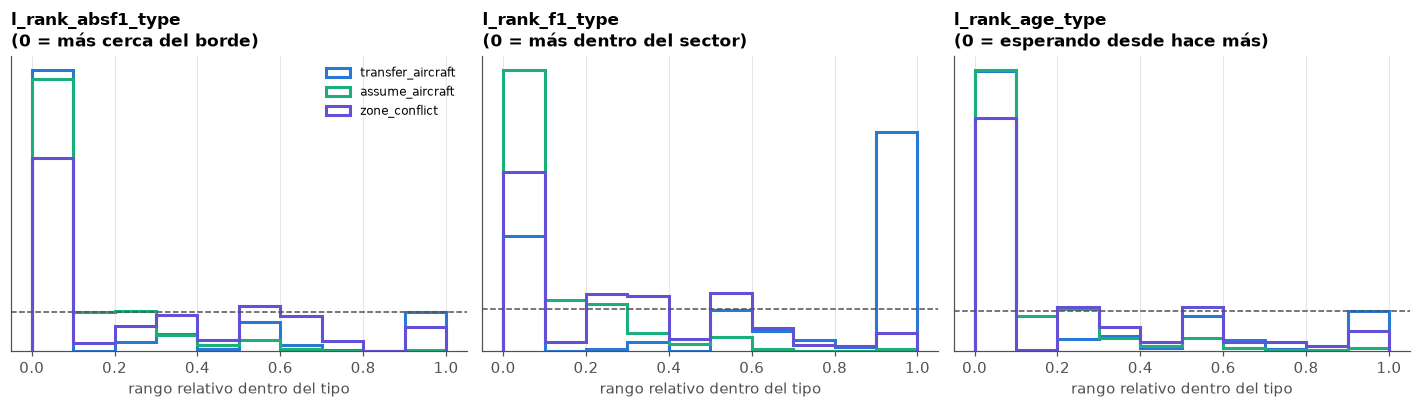

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, ttl in zip(axes, ["l_rank_absf1_type", "l_rank_f1_type", "l_rank_age_type"],
                        ["más cerca del borde", "más dentro del sector", "esperando desde hace más"]):
    for ty, c in zip(["transfer_aircraft", "assume_aircraft", "zone_conflict"], [C["blue"], C["aqua"], C["violet"]]):
        g = pos[pos.type == ty]
        r = ((g[col] - 1) / (g.l_n_type - 1).clip(lower=1)).clip(0, 1)   # rango relativo 0..1
        ax.hist(r, bins=np.linspace(0, 1, 11), density=True, histtype="step", lw=2, color=c, label=ty)
    ax.axhline(1, color=C["ink2"], ls="--", lw=1)
    ax.set(title=f"{col}\n(0 = {ttl})", xlabel="rango relativo dentro del tipo", yticks=[])
axes[0].legend(fontsize=8); plt.tight_layout()
r1 = pd.DataFrame({ty: pos[pos.type == ty].groupby("fold").l_rank_absf1_type.apply(lambda r: (r == 1).mean())
                   for ty in ["transfer_aircraft", "assume_aircraft", "zone_conflict"]})
print("P(la elegida es la más cercana al borde de su tipo), por fold:"); print(r1.round(2).to_string())

**Lectura:** la línea discontinua es «al azar». Para `transfer` y `assume` la elegida suele ser la más próxima al borde (FIFO espacial), pero con mucha masa en otros rangos (estilo del controlador + ruido de etiquetado).

Vista general: media del z-score **dentro de la muestra** de la elegida, para todas las numéricas, por fold. Una barra solo es fiable si los 5 folds coinciden en signo.

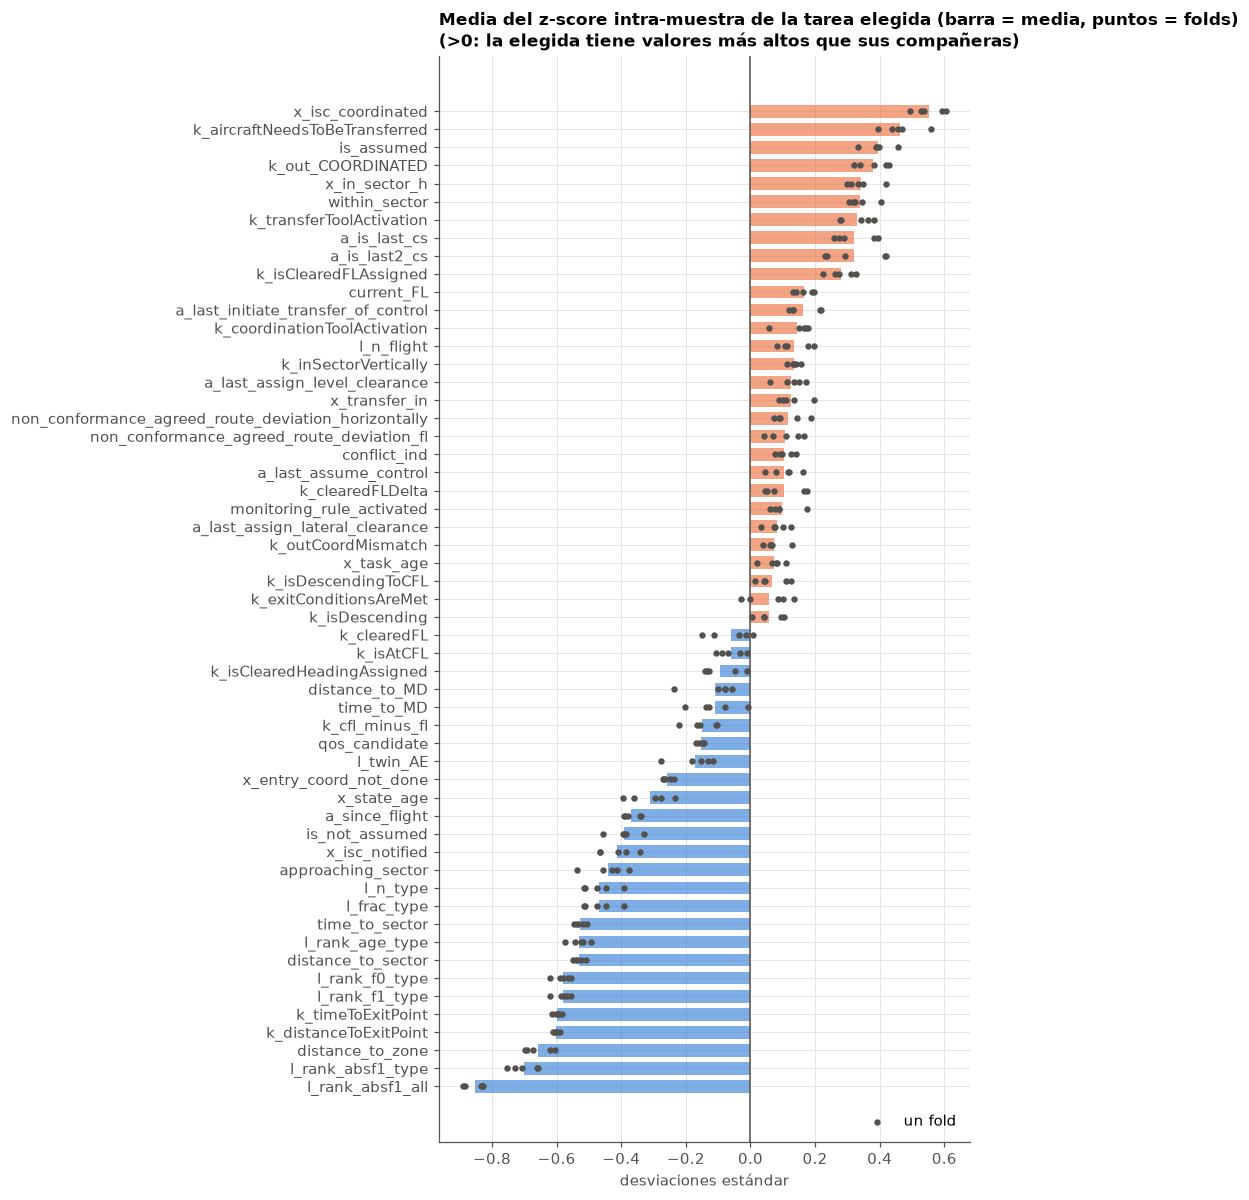

In [14]:
# z-score dentro de cada muestra -> elimina diferencias entre snapshots
gb = lab[num].groupby(lab.sample_id)
z = (lab[num] - gb.transform("mean")) / (gb.transform("std") + 1e-9)
eff_f = z[lab.target_index == 1].groupby(lab.fold).mean().T
eff_f = eff_f[eff_f.mean(axis=1).abs() > 0.05]
eff_f = eff_f.loc[eff_f.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(9, 11))
m = eff_f.mean(axis=1)
ax.barh(eff_f.index, m, color=[TARGET if v > 0 else OTHER for v in m], height=0.7, alpha=0.6)
for f in range(5): ax.scatter(eff_f[f], eff_f.index, s=10, color=C["ink2"], zorder=3, label="un fold" if f == 0 else None)
ax.axvline(0, color=C["ink2"], lw=1); ax.legend(loc="lower right")
ax.set(title="Media del z-score intra-muestra de la tarea elegida (barra = media, puntos = folds)\n(>0: la elegida tiene valores más altos que sus compañeras)",
       xlabel="desviaciones estándar"); plt.tight_layout()

## 6 · Poder de cada feature como ranker (por fold) y correlaciones

Para cada feature ordenamos las tareas de cada muestra por ella (NaN al final) y calculamos el top-3 hit rate. El **sentido** (alto o bajo primero) se elige en los otros 4 folds y se mide en el apartado, igual que el prior por tipo: así la cifra es comparable con la CV de los modelos.

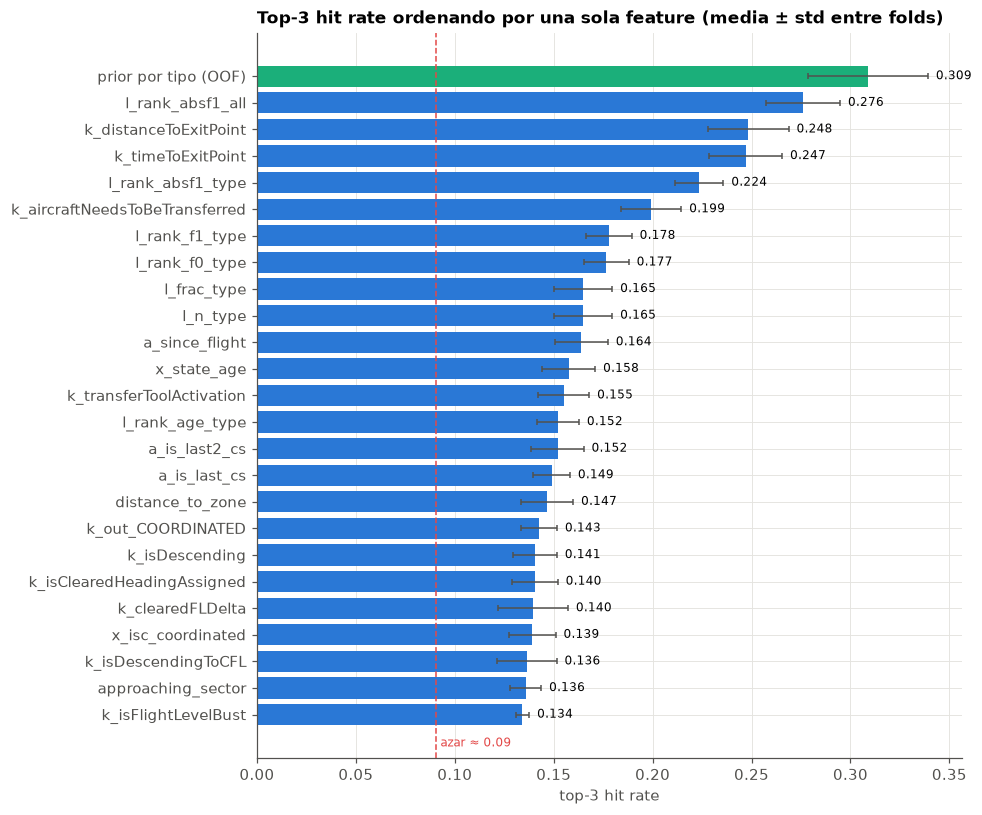

In [15]:
def hits(df, score):
    # acierto top-3 por muestra (Series indexada por sample_id), ordenando por score descendente (NaN al final)
    r = pd.Series(score, index=df.index).fillna(-np.inf).groupby(df.sample_id.values).rank(ascending=False, method="first")
    m = df.target_index == 1
    return pd.Series((r[m] <= 3).values, index=df.sample_id[m].values)

S_FOLD = smp.set_index("sample_id").fold
def by_fold(h): return h.groupby(S_FOLD.reindex(h.index).values).mean()

res = {}
for c in num:
    x = lab[c].astype(float)
    up, dn = by_fold(hits(lab, x)), by_fold(hits(lab, -x))
    w = smp.groupby("fold").size()
    # sentido elegido con los otros 4 folds (media ponderada por muestras)
    oof = [up[f] if np.average(up.drop(f), weights=w.drop(f)) >= np.average(dn.drop(f), weights=w.drop(f)) else dn[f] for f in range(5)]
    res[c] = pd.Series(oof, index=range(5))
uni = pd.DataFrame(res).T

# referencia: prior por tipo ajustado en los otros 4 folds
pr = pd.Series(0.0, index=lab.index)
for f in range(5):
    p = pos[pos.fold != f].task_index.value_counts(normalize=True)
    pr[lab.fold == f] = lab.task_index[lab.fold == f].map(p).fillna(0)
uni.loc["prior por tipo (OOF)"] = by_fold(hits(lab, pr))
uni["media"], uni["std"] = uni[list(range(5))].mean(axis=1), uni[list(range(5))].std(axis=1)
top = uni.sort_values("media", ascending=False).head(25)

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(top.index[::-1], top.media[::-1], xerr=top["std"][::-1], color=[C["aqua"] if i.startswith("prior") else OTHER for i in top.index[::-1]],
        error_kw=dict(ecolor=C["ink2"], lw=1, capsize=2))
rnd = (3 / smp.seq_len).mean()
ax.axvline(rnd, color=C["red"], ls="--", lw=1); ax.text(rnd, -1.2, f" azar ≈ {rnd:.2f}", color=C["red"], fontsize=8)
for i, (v, s) in enumerate(zip(top.media[::-1], top["std"][::-1])): ax.text(v + s + 0.004, i, f"{v:.3f}", va="center", fontsize=8)
ax.set(title="Top-3 hit rate ordenando por una sola feature (media ± std entre folds)", xlabel="top-3 hit rate"); plt.tight_layout()

Text(0.5, 1.0, 'Correlación de Spearman entre features (clustering jerárquico)')

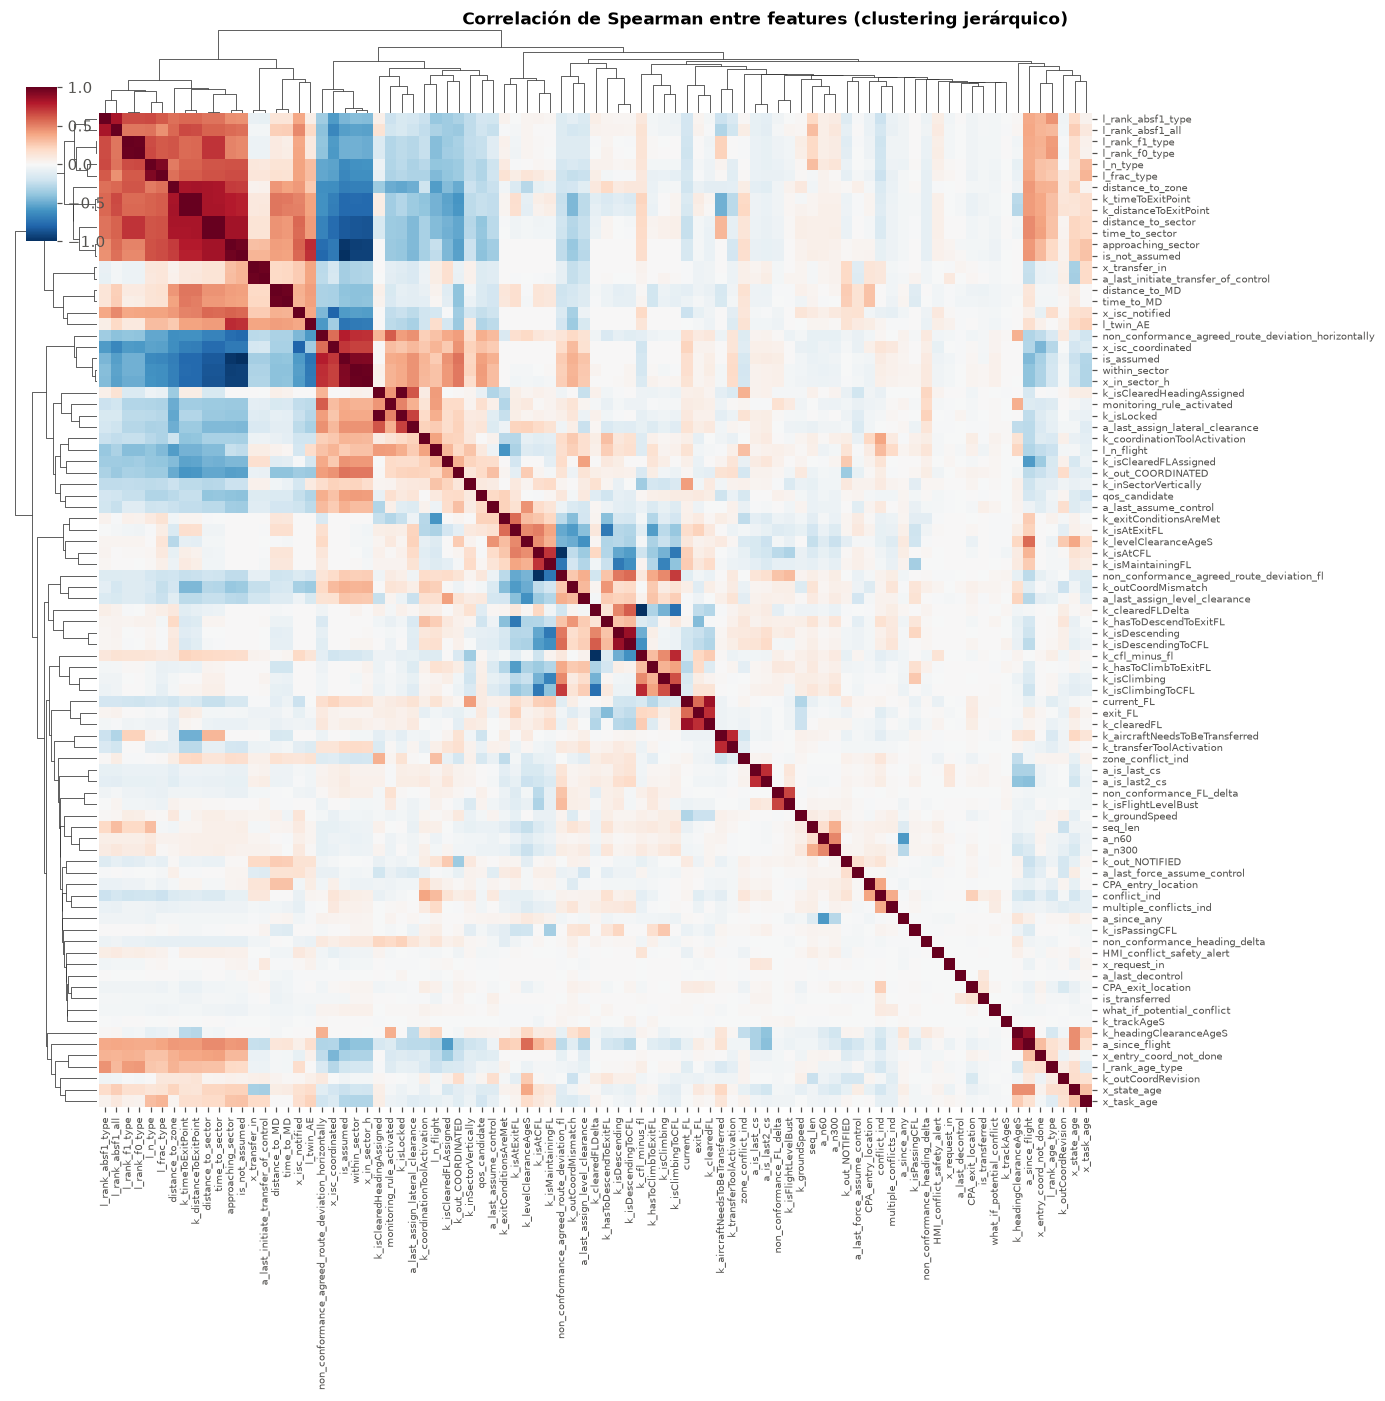

In [16]:
# Correlación entre features (Spearman sobre una muestra de filas), agrupada jerárquicamente
sub = lab[num].sample(60000, random_state=0)
keep = [c for c in num if sub[c].nunique() > 1 and sub[c].notna().mean() > 0.1]
corr = sub[keep].corr("spearman").fillna(0)
cg = sns.clustermap(corr, cmap="RdBu_r", vmin=-1, vmax=1, figsize=(14, 14), xticklabels=True, yticklabels=True,
                    cbar_pos=(0.02, 0.85, 0.02, 0.1), dendrogram_ratio=0.08)
cg.ax_heatmap.tick_params(labelsize=6.5); cg.fig.suptitle("Correlación de Spearman entre features (clustering jerárquico)", x=0.5, y=1.0, weight="bold")

In [17]:
# Pares casi redundantes (|rho| > 0.95): candidatos a eliminar
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
pairs[pairs.abs() > 0.95].sort_values(key=abs, ascending=False).round(3).to_frame("rho")

,,rho
k_clearedFLDelta,k_cfl_minus_fl,-1.000
k_isClearedHeadingAssigned,k_isLocked,1.000
distance_to_sector,time_to_sector,0.999
is_assumed,is_not_assumed,-0.998
non_conformance_agreed_route_deviation_fl,k_isAtCFL,-0.997
k_timeToExitPoint,k_distanceToExitPoint,0.996
within_sector,x_in_sector_h,0.988
l_rank_f1_type,l_rank_f0_type,0.986
x_transfer_in,a_last_initiate_transfer_of_control,0.983
distance_to_MD,time_to_MD,0.982


**Lectura:** hay bloques muy redundantes (distancia ↔ tiempo al sector, `within_sector` ↔ `x_in_sector_h`, `is_assumed` ↔ `is_not_assumed`, familias `k_` de nivel). Para árboles no es grave; para modelos lineales/NN conviene podar o comprimir (sección 7). Las features con std alta entre folds dependen del controlador: cuidado con ellas.

## 7 · PCA

Para ver cuántas direcciones independientes hay de verdad en las numéricas y si alguna separa a la elegida. Preproceso: vacío → mediana + indicador de vacío (solo columnas con >1 % de vacíos), luego estandarizar.

Se ajusta **un PCA por fold** (con los otros 4 folds, para que los componentes se puedan usar como feature sin fuga) y **uno con todo lo etiquetado** (para test). Todos los pesos (mediana, media, escala, componentes) se guardan en `models/pca_eda.npz`; si el archivo existe y coincide con las columnas actuales, se carga en vez de reajustar. Para reajustar, borrar el archivo.

In [18]:
from sklearn.decomposition import PCA

PCA_FILE = MODELS / "pca_eda.npz"
NA_COLS = [c for c in num if lab[c].isna().mean() > 0.01]
N_PC = 20

def pca_fit(X):
    med = np.nanmedian(X[num].values, axis=0)
    A = np.hstack([np.where(np.isnan(X[num].values), med, X[num].values), X[NA_COLS].isna().values])
    mu, sd = A.mean(0), A.std(0) + 1e-9
    p = PCA(N_PC, random_state=0).fit((A - mu) / sd)
    return dict(med=med, mu=mu, sd=sd, comp=p.components_, var=p.explained_variance_ratio_)

def pca_apply(X, w):
    A = np.hstack([np.where(np.isnan(X[num].values), w["med"], X[num].values), X[NA_COLS].isna().values])
    return ((A - w["mu"]) / w["sd"]) @ w["comp"].T

keys = ["all"] + [f"fold{f}" for f in range(5)]
cached = PCA_FILE.exists() and list(np.load(PCA_FILE, allow_pickle=True)["cols"]) == num
if cached:
    z_ = np.load(PCA_FILE, allow_pickle=True)
    W = {k: {p: z_[f"{k}_{p}"] for p in ("med", "mu", "sd", "comp", "var")} for k in keys}
    print("PCA cargado de", PCA_FILE)
else:
    W = {"all": pca_fit(lab)} | {f"fold{f}": pca_fit(lab[lab.fold != f]) for f in range(5)}
    for f in range(5):   # el signo de cada componente es arbitrario: lo alineamos con el PCA global
        w = W[f"fold{f}"]; w["comp"] *= np.sign((w["comp"] * W["all"]["comp"]).sum(1, keepdims=True))
    MODELS.mkdir(exist_ok=True)
    np.savez(PCA_FILE, cols=np.array(num, dtype=object), na_cols=np.array(NA_COLS, dtype=object),
             **{f"{k}_{p}": v for k, w in W.items() for p, v in w.items()})
    print("PCA ajustado y guardado en", PCA_FILE)

# proyección OOF: cada fold con el PCA ajustado sin él
PC = np.zeros((len(lab), N_PC))
for f in range(5):
    m = (lab.fold == f).values
    PC[m] = pca_apply(lab[m], W[f"fold{f}"])
pcs = pd.DataFrame(PC, index=lab.index, columns=[f"pc{i+1}" for i in range(N_PC)])

PCA ajustado y guardado en /home/jm/proyectos/FlowDataLab/models/pca_eda.npz


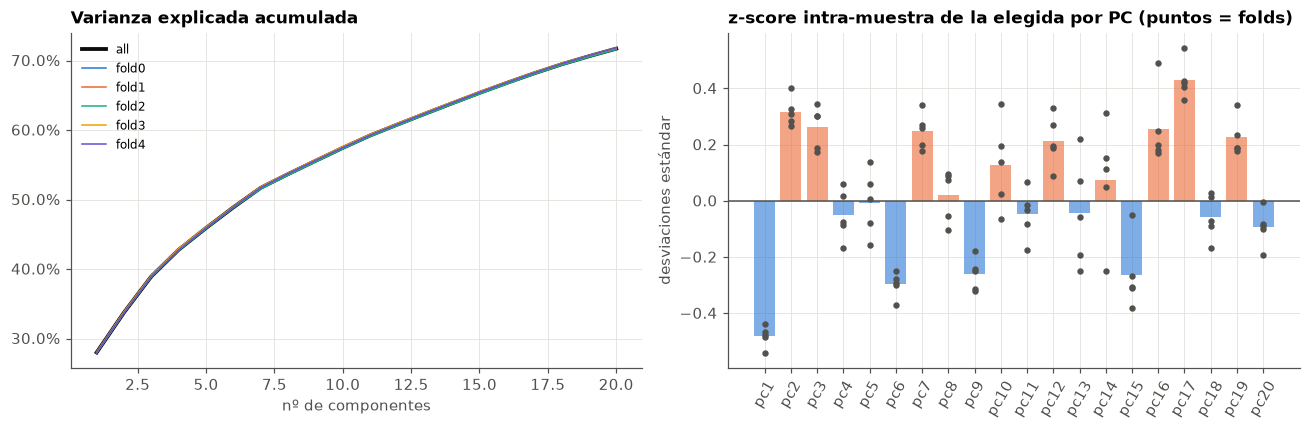

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, c in zip(keys, [C["ink"]] + FOLD_C):
    ax[0].plot(np.arange(1, N_PC + 1), np.cumsum(W[k]["var"]), color=c, lw=2.5 if k == "all" else 1, label=k)
ax[0].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax[0].legend(fontsize=8)
ax[0].set(title="Varianza explicada acumulada", xlabel="nº de componentes")

# z-score intra-muestra de cada PC en la elegida, por fold (como en la sección 5)
gb = pcs.groupby(lab.sample_id)
zp = ((pcs - gb.transform("mean")) / (gb.transform("std") + 1e-9))[lab.target_index == 1].groupby(lab.fold).mean().T
ax[1].bar(zp.index, zp.mean(axis=1), color=[TARGET if v > 0 else OTHER for v in zp.mean(axis=1)], alpha=0.6)
for f in range(5): ax[1].scatter(zp.index, zp[f], s=10, color=C["ink2"], zorder=3)
ax[1].axhline(0, color=C["ink2"], lw=1); plt.setp(ax[1].get_xticklabels(), rotation=60)
ax[1].set(title="z-score intra-muestra de la elegida por PC (puntos = folds)", ylabel="desviaciones estándar")
plt.tight_layout()

In [20]:
# Qué columnas pesan en las PCs que más separan a la elegida (PCA con todo)
names = num + [f"na_{c}" for c in NA_COLS]
best = zp.mean(axis=1).abs().sort_values(ascending=False).index[:3]
load = pd.DataFrame({p: pd.Series(W["all"]["comp"][int(p[2:]) - 1], index=names) for p in best})
pd.concat([load[p].abs().sort_values(ascending=False).head(8).index.to_series(name=p).reset_index(drop=True) for p in best], axis=1)

,pc1,pc17,pc2
0,na_k_isMaintainingFL,k_isFlightLevelBust,a_last_initiate_transfer_of_control
1,na_k_isDescending,non_conformance_FL_delta,x_transfer_in
2,na_k_isClearedHeadingAssigned,k_aircraftNeedsToBeTransferred,l_twin_AE
3,is_assumed,k_transferToolActivation,conflict_ind
4,na_k_isClimbing,current_FL,na_distance_to_MD
5,na_k_hasToClimbToExitFL,qos_candidate,na_time_to_MD
6,na_k_isAtExitFL,k_isDescendingToCFL,l_rank_absf1_type
7,na_k_hasToDescendToExitFL,k_inSectorVertically,l_n_flight


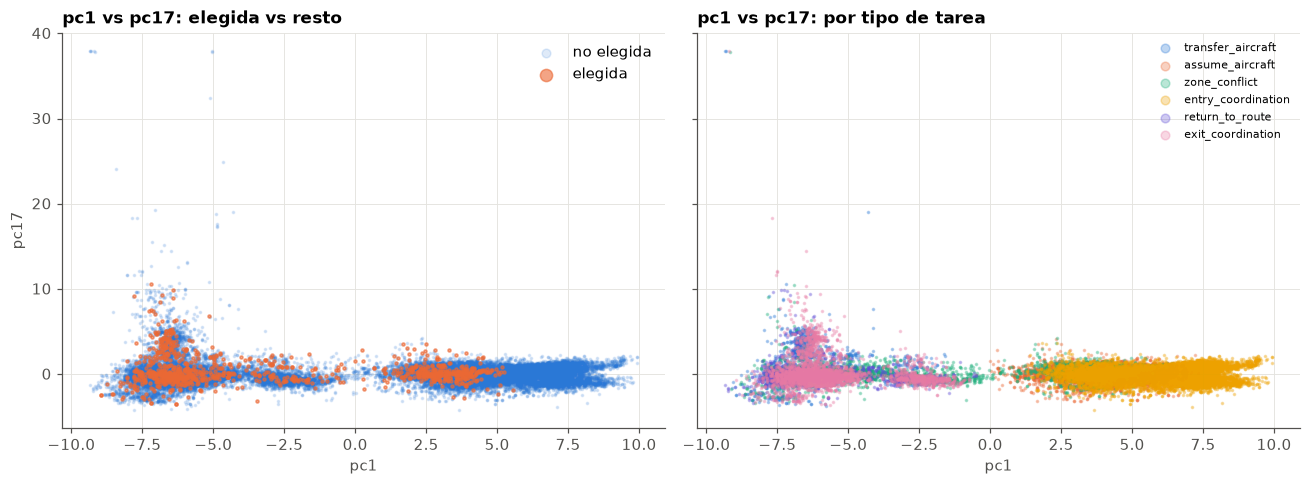

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
s = pcs.join(lab[["target_index", "type"]]).sample(40000, random_state=0)
p1, p2 = best[:2]
axes[0].scatter(s[s.target_index == 0][p1], s[s.target_index == 0][p2], s=2, color=OTHER, alpha=0.15, label="no elegida")
axes[0].scatter(s[s.target_index == 1][p1], s[s.target_index == 1][p2], s=4, color=TARGET, alpha=0.6, label="elegida")
axes[0].legend(markerscale=4); axes[0].set(title=f"{p1} vs {p2}: elegida vs resto", xlabel=p1, ylabel=p2)
for ty, c in zip(top_types, [C["blue"], C["orange"], C["aqua"], C["yellow"], C["violet"], C["magenta"]]):
    q = s[s.type == ty]; axes[1].scatter(q[p1], q[p2], s=2, color=c, alpha=0.3, label=ty)
axes[1].legend(markerscale=4, fontsize=7); axes[1].set(title=f"{p1} vs {p2}: por tipo de tarea", xlabel=p1)
plt.tight_layout()

**Lectura:** la varianza está repartida (PC1 ≈ 28 %, 10 componentes ≈ 57 %, 20 ≈ 72 %), pero las curvas de los 5 folds coinciden, así que la estructura es la misma para todos los controladores. PC1 es básicamente «avión asumido o no» (indicadores de vacío de los `k_*` + `is_assumed`). Las PCs que más separan a la elegida son mezclas de transfer/estado del avión y, como ranker, la mejor (≈ 0.21) queda por debajo de `l_rank_absf1_all` (≈ 0.28) y del prior por tipo (≈ 0.31): para ranking importa la posición *relativa* dentro de la muestra, que el PCA no captura. Si alguien quiere probarlas como feature (p. ej. en la NN), cargar `models/pca_eda.npz` y usar `fold{f}` para el OOF y `all` para test (los signos ya están alineados entre folds).

## 8 · Conclusiones (solo con el propio snapshot)

1. Es un problema de *ranking* intra-snapshot: lo que importa es comparar tareas de la misma muestra, no valores absolutos.
2. **El tipo de tarea** fija mucho (transfer/assume = 50 % de respuestas) y **la cercanía al borde, por tipo**, decide el avión dentro del tipo (assume antes de entrar, transfer antes de salir).
3. **Caso twin** (assume + entry_coordination del mismo avión): se elige assume ~3 de cada 4 veces; es donde las columnas del avión no discriminan.
4. **Estilo humano**: la mezcla de tipos y el poder de algunas features varían entre folds/controladores; el techo no es 100 %. Preferir features cuyo efecto tenga el mismo signo en los 5 folds.
5. Los NaN son estructurales (no asumido / sin conflicto / sin zona): dejarlos como NaN o indicador, nunca 0.
6. Hay mucha redundancia entre pares de columnas (|ρ| > 0.95), pero la varianza total está repartida: el PCA (pesos en `models/pca_eda.npz`) es estable entre folds y no aporta un ranker mejor que las features `l_rank_*` existentes.

**Ideas de features para `features.py`** (todas dentro del `sample_id`): rangos dentro del tipo de `|time_to_sector|`, `x_task_age`, `a_since_flight`; indicadores de vacío con efecto estable; flags del twin; contexto de la lista (nº de aviones, nº de tareas de cada tipo).

> Fuera de este notebook: modelos y ablaciones (`src/m_*.py`), análisis de errores sobre OOF (`notebooks/errores_*.ipynb`) y todo lo que use otros snapshots de la sesión (prohibido por ahora, regla 1).

## 9 · Plan de Acción y Directrices para `features.py` (Para Adri)

Tras cruzar el OOF del modelo LightGBM base con el modelo con "todas" las variables, estas son las reglas de oro para la próxima iteración.

### 🚫 LA LISTA NEGRA: Variables que NO hay que usar como features
- **`row_index`**: Descartada por completo. La posición en la lista no aporta información (está ordenada alfabéticamente por *callsign*).
- **El Bloque de IDs**: `sample_id`, `session`, `atco`, `scenario`, `timestamp`, `task_name`. (Solo sirven para agrupar o alinear).
- **Las variables del futuro (`f_next_input`, `f_task_end`)**: No las usamos en la CV oficial porque violan la regla 1 y el principio de asistencia en tiempo real.
- **Rellenar NaNs con Ceros**: Prohibido imputar con `0` las variables `k_*` (estado del avión) o `distance_to_MD`. Los NaNs son estructurales y significan "no aplica/no asumido". Cread indicadores booleanos (ej. `is_k_nan = df['k_timeToExitPoint'].isna()`) o dejad que LightGBM los gestione de forma nativa.

### 🥇 LA LISTA DE ORO: Nuevas features a probar (una a una)
El modelo "Base" supera al de "Todos" los features porque meter variables en bloque añade ruido a las clases minoritarias. Prueba a inyectar estas features individualmente:

1. **El Oráculo (Prior Colectivo Alineado)**
   - **Qué es:** Qué hacían los otros controladores en este mismo segundo del escenario.
   - **Implementación:** Usa `cp_cs` y `cp_task`. Calculado siempre con *leave-one-ATCO-out* para evitar Target Leakage en validación cruzada.

2. **Penalizador de Gemelos de Entrada (`is_entry_losing`)**
   - **Por qué:** En los 5 folds, los controladores prefieren el `assume` (68-78% de las veces) cuando compite con `entry_coordination` en el mismo avión.
   - **Implementación:** `df['is_entry_losing'] = (df['task_index'] == 2) * df['l_twin_AE']` (Hunde la prioridad de la coordinación de entrada).

3. **Penalizador de Gemelos de Salida (Rescate del `exit_coordination`)**
   - **Por qué:** El modelo tiene solo un 9.4% de acierto en las coordinaciones de salida porque se confunde con el `transfer_aircraft` (86% de acierto). 
   - **Implementación:** Crea un cruce entre `task_index == 3` (exit_coordination) y variables del sector vecino, como `k_out_NOTIFIED` o `k_out_COORDINATED`.

4. **Alertas Físicas para Conflictos**
   - **Por qué:** Acierto pobre del ~30% en `conflict_resolution`.
   - **Implementación:** Dar más peso o crear rankings relativos basados en la señal `HMI_conflict_safety_alert` (la alerta visual en pantalla).

5. **Estrategia FIFO Espacial (Confirmada)**
   - **Por qué:** Domina las mayoritarias (`assume` y `transfer`).
   - **Implementación:** Mantener y asegurar el ranking de la distancia al borde **intra-tipo** (`l_rank_absf1_type`).